In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import pickle
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import kagglehub

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
print("Downloading dataset...")
dataset_path = kagglehub.dataset_download("mohamedasak/chest-x-ray-6-classes-dataset")
print(f"Dataset path: {dataset_path}")

def find_subdir(root, target):
    for dirpath, dirnames, filenames in os.walk(root):
        for d in dirnames:
            if target.lower() in d.lower():
                return os.path.join(dirpath, d)
    return None

train_path = find_subdir(dataset_path, "train")
val_path = find_subdir(dataset_path, "val")
test_path = find_subdir(dataset_path, "test")

print(f"Train: {train_path}")
print(f"Val: {val_path}")
print(f"Test: {test_path}")

# Get class names
CLASS_NAMES =sorted(os.listdir(train_path))
NUM_CLASSES = len(CLASS_NAMES)
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")

Using Colab cache for faster access to the 'chest-x-ray-6-classes-dataset' dataset.
Dataset path: /kaggle/input/chest-x-ray-6-classes-dataset
Train: /kaggle/input/chest-x-ray-6-classes-dataset/chest-xray/train
Val: /kaggle/input/chest-x-ray-6-classes-dataset/chest-xray/val
Test: /kaggle/input/chest-x-ray-6-classes-dataset/chest-xray/test
Classes (6): ['Covid-19', 'Emphysema', 'Normal', 'Pneumonia-Bacterial', 'Pneumonia-Viral', 'Tuberculosis']


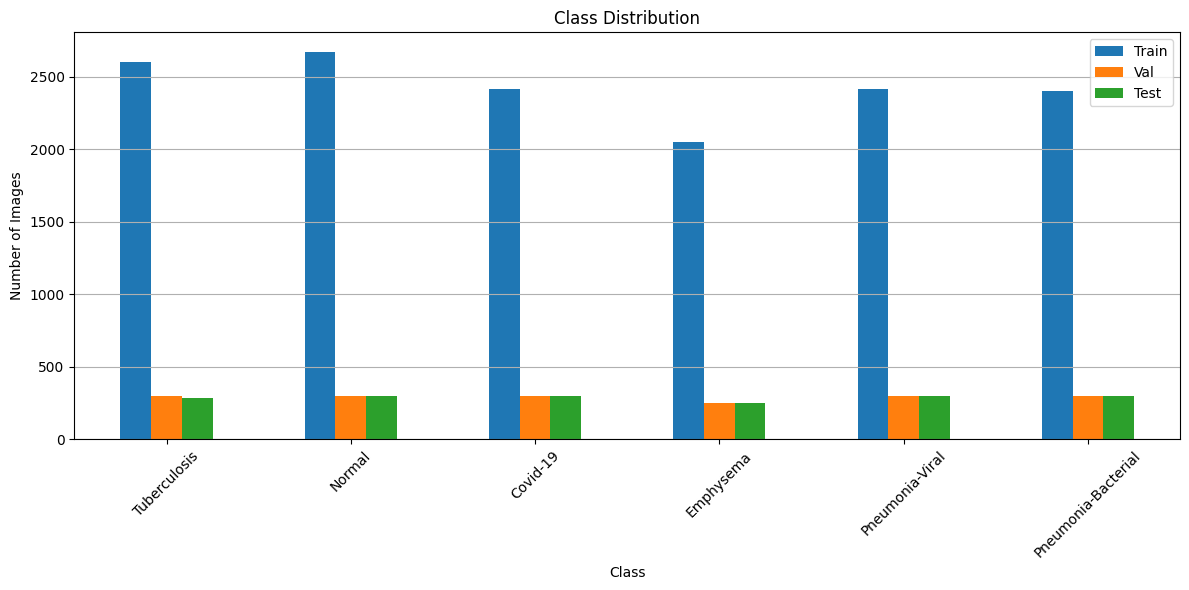

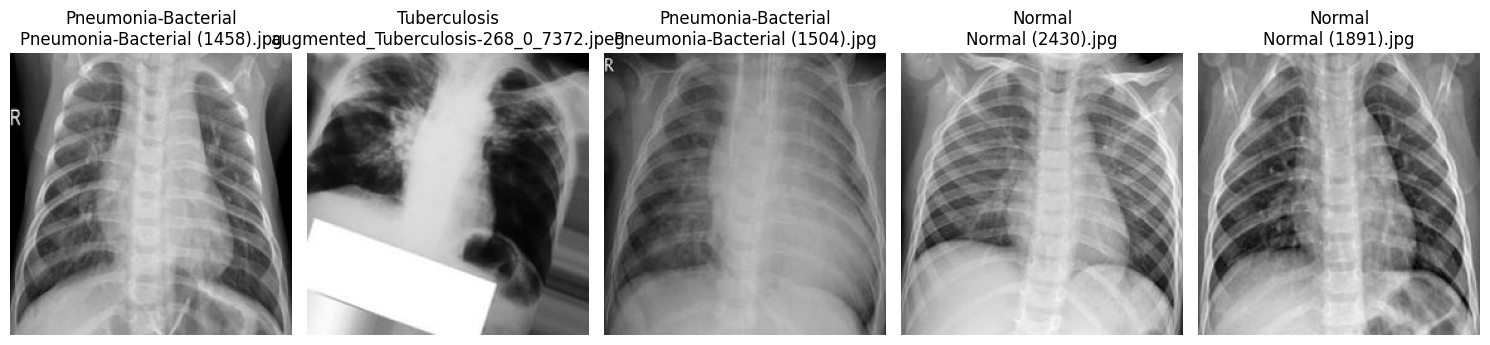

In [4]:
import pandas as pd

def count_images(path):
    counts = {}
    for cls in os.listdir(path):
        cls_path = os.path.join(path, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_counts = count_images(train_path)
val_counts = count_images(val_path)
test_counts = count_images(test_path)

df = pd.DataFrame([train_counts, val_counts, test_counts],
                  index=["Train", "Val", "Test"]).fillna(0).astype(int)

df.T.plot(kind='bar', figsize=(12,6))
plt.title("Class Distribution")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Show 5 random sample images
def show_samples(path, n=5):
    classes = os.listdir(path)
    fig, axes = plt.subplots(1, n, figsize=(15,5))
    for i in range(n):
        cls = random.choice(classes)
        cls_path = os.path.join(path, cls)
        img_name = random.choice(os.listdir(cls_path))
        img_path = os.path.join(cls_path, img_name)
        img = plt.imread(img_path)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"{cls}\n{img_name}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

show_samples(train_path, n=5)

In [9]:
from PIL import Image

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transforms (with augmentation)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Validation/Test transforms (no augmentation)
val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

class ChestXRayDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        self.samples = []
        for cls in self.classes:
            cls_path = os.path.join(root_dir, cls)
            for img_name in os.listdir(cls_path):
                self.samples.append((os.path.join(cls_path, img_name), self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

train_dataset = ChestXRayDataset(train_path, transform=train_transform)
val_dataset = ChestXRayDataset(val_path, transform=val_transform)
test_dataset = ChestXRayDataset(test_path, transform=val_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 14551, Val: 1748, Test: 1737


In [ ]:
    from torchvision import models

    model = models.efficientnet_b0(weights="IMAGENET1K_V1")

    num_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.2, inplace=True),
        nn.Linear(num_features, NUM_CLASSES)
    )

    model.to(device)
    print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Total parameters: 4,015,234


In [11]:
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR

EPOCHS = 30
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

In [12]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    pbar = tqdm(loader, desc="Training")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
        pbar.set_postfix({'loss': loss.item()})
    return total_loss / len(loader), 100. * correct / total

def validate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
    return total_loss / len(loader), 100. * correct / total

# Training history
train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_acc = 0.0

for epoch in range(1, EPOCHS+1):
    print(f"\nEpoch {epoch}/{EPOCHS}")
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = validate(model, val_loader, criterion)
    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Train Loss: {train_loss:.2f}, Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.2f}, Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_efficientnet.pth")
        print(f"✓ New best model saved (Val Acc: {val_acc:.2f}%)")


Epoch 1/30


Validating: 100%|██████████| 55/55 [00:09<00:00,  5.75it/s]


Train Loss: 0.81, Train Acc: 68.76%
Val Loss: 0.49, Val Acc: 80.61%
✓ New best model saved (Val Acc: 80.61%)

Epoch 2/30


Validating: 100%|██████████| 55/55 [00:06<00:00,  9.16it/s]


Train Loss: 0.53, Train Acc: 78.58%
Val Loss: 0.37, Val Acc: 84.90%
✓ New best model saved (Val Acc: 84.90%)

Epoch 3/30


...

Train Loss: 0.20, Train Acc: 92.15%
Val Loss: 0.21, Val Acc: 93.08%

Epoch 29/30


Validating: 100%|██████████| 55/55 [00:05<00:00,  9.32it/s]


Train Loss: 0.19, Train Acc: 92.43%
Val Loss: 0.21, Val Acc: 92.85%

Epoch 30/30


Validating: 100%|██████████| 55/55 [00:06<00:00,  8.94it/s]

Train Loss: 0.20, Train Acc: 92.14%
Val Loss: 0.20, Val Acc: 93.02%


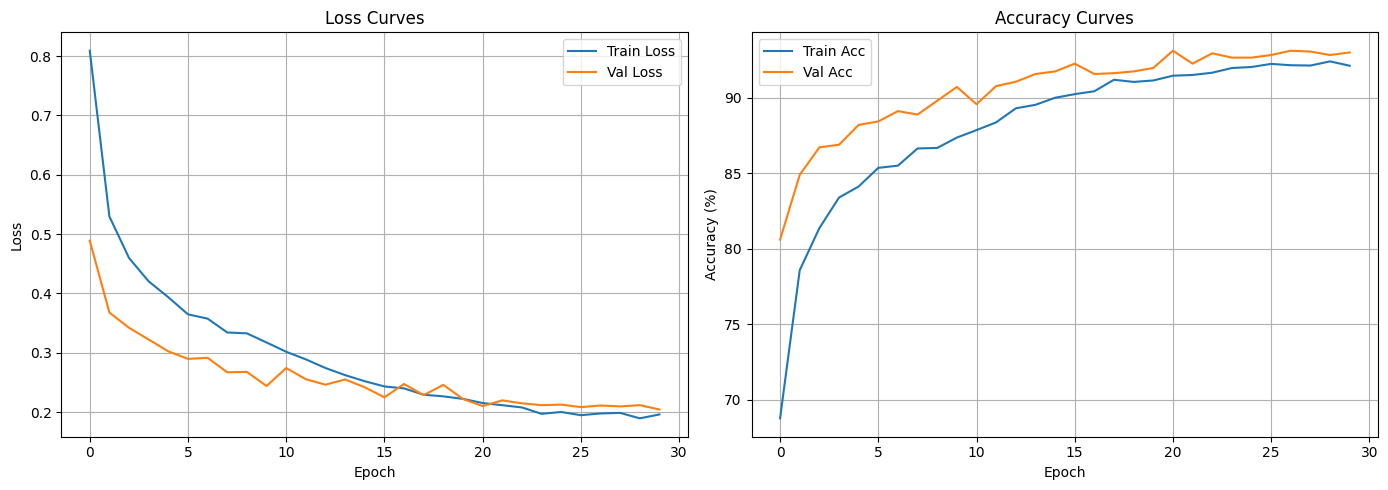

In [13]:
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curves')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Curves')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Testing: 100%|██████████| 55/55 [00:17<00:00,  3.21it/s]


Test Accuracy: 0.9424
Test F1-Score (weighted): 0.9424


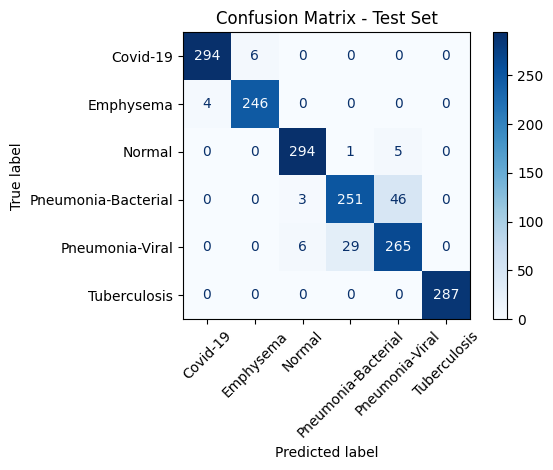

In [14]:
# Load best model
model.load_state_dict(torch.load("best_efficientnet.pth"))
model.eval()

all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Metrics
accuracy = accuracy_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds, average='weighted')
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test F1-Score (weighted): {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.show()

In [15]:
# Save class names as pickle
with open("class_names.pkl", "wb") as f:
    pickle.dump(CLASS_NAMES, f)

# Download both files
from google.colab import files
files.download("best_efficientnet.pth")
files.download("class_names.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from sklearn.metrics import classification_report
import torch
from tqdm import tqdm

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Inference for report"):
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())


report = classification_report(
    all_labels,
    all_preds,
    target_names=CLASS_NAMES,
    digits=4
)

print("\n" + "="*60)
print("CLASSIFICATION REPORT - TEST SET")
print("="*60)
print(report)


Inference for report: 100%|██████████| 55/55 [00:05<00:00, 10.82it/s]


CLASSIFICATION REPORT - TEST SET
                     precision    recall  f1-score   support

           Covid-19     0.9866    0.9800    0.9833       300
          Emphysema     0.9762    0.9840    0.9801       250
             Normal     0.9703    0.9800    0.9751       300
Pneumonia-Bacterial     0.8932    0.8367    0.8640       300
    Pneumonia-Viral     0.8386    0.8833    0.8604       300
       Tuberculosis     1.0000    1.0000    1.0000       287

           accuracy                         0.9424      1737
          macro avg     0.9442    0.9440    0.9438      1737
       weighted avg     0.9428    0.9424    0.9424      1737



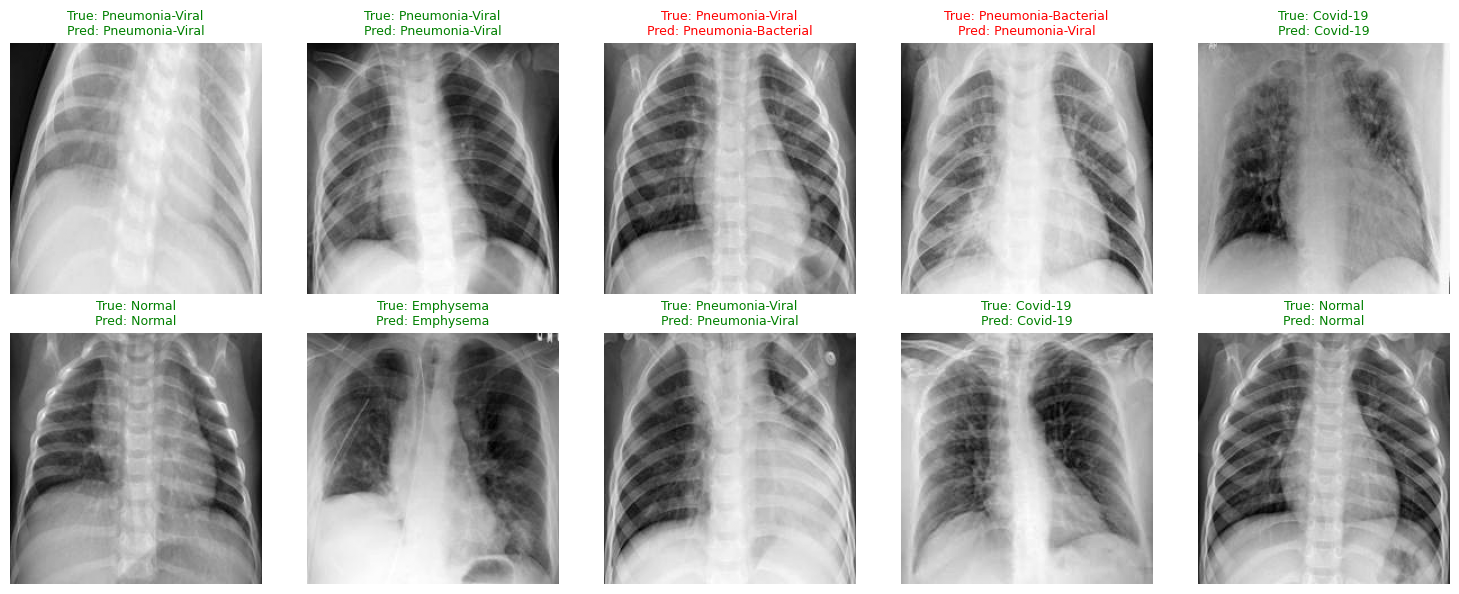

In [18]:
import random
import cv2
import matplotlib.pyplot as plt

def show_random_predictions(model, dataset, class_names, num_images=10):
    """
    Display random images from the dataset with true and predicted labels.
    model: EfficientNet-B0 model (already loaded and in eval mode)
    dataset: test dataset (ChestXRayDataset)
    class_names: list of class names (order must match model's output)
    num_images: number of images to display (default 10)
    """
    model.eval()
    device = next(model.parameters()).device
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()
    indices = random.sample(range(len(dataset)), num_images)

    for i, idx in enumerate(indices):
        # Get image tensor and true label from dataset
        img_tensor, true_label = dataset[idx]
        # Get original image path for display (grayscale)
        img_path, _ = dataset.samples[idx]
        orig_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        # Display original grayscale image
        axes[i].imshow(orig_img, cmap='gray')
        axes[i].axis('off')

        # Run inference on the tensor (already on CPU, move to device)
        input_tensor = img_tensor.unsqueeze(0).to(device)
        with torch.no_grad():
            outputs = model(input_tensor)
            _, pred = outputs.max(1)

        true_name = class_names[true_label]
        pred_name = class_names[pred.item()]
        color = 'green' if true_label == pred.item() else 'red'
        axes[i].set_title(f"True: {true_name}\nPred: {pred_name}", color=color, fontsize=9)

    plt.tight_layout()
    plt.show()

# Call the function with your trained EfficientNet model
show_random_predictions(model, test_dataset, CLASS_NAMES, num_images=10)